# ETHICS Gender Persona - Template Reusable Akurasi

Notebook ini mempertahankan gaya analisis ETHICS gender yang dipakai untuk
visual Bab VI: heatmap efek berpasangan dengan empat panel subset. Template
ini juga menyediakan tabel akurasi penuh, status respons, metadata token, dan
indeks artefak agar dapat diadaptasi untuk persona lain.

Angka inferensial diambil dari bundle v3 tervalidasi. Notebook tidak melakukan
API call, inference, parsing ulang, rescoring, atau perhitungan ulang uji
statistik.

## 0. Provenance dan validation gate

In [8]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, display

start = Path.cwd().resolve()
REPO_ROOT = next(
    path for path in [start, *start.parents]
    if (path / "AGENTS.md").exists() and (path / "src").exists()
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from src.MAIN_PARSING.ETHICS.build_gender_publication_notebook_v4_reusable import run_analysis

result = run_analysis()
OUTPUT_DIR = Path(result["output_dir"])
FIGURE_DIR = OUTPUT_DIR / "figures"
display(pd.Series(result["validation"], name="value").to_frame())
assert result["validation"]["valid"] is True

[INFO] Bundle reusable versi lama diperbarui: ethics-gender-v4-reusable-20260905-3 -> ethics-gender-v4-reusable-20260905-2
[INFO] Bundle baru parsial dilanjutkan: D:\TugasAkhir\result\ETHICS\reports\Gender_Persona\_combined\persona_publication_analysis_v4_reusable_gender_first_six_models


,value
valid,True
analysis_version,ethics-gender-v4-reusable-20260905-2
source_analysis_version,ethics-gender-v3-accuracy-paired-holm-20260821
source_validation_valid,True
source_v3_bundle,D:\TugasAkhir\result\ETHICS\reports\Gender_Per...
source_csv,D:\TugasAkhir\result\ETHICS\reports\Gender_Per...
responses,81756
questions,1514
models,6
conditions,9


## 1. Akurasi penuh untuk setiap kondisi dan subset

Akurasi penuh menggunakan seluruh respons pada kondisi sebagai penyebut.
Kolom `accuracy_committed` disajikan sebagai metrik tambahan dan harus dibaca
bersama `commit_rate`; `abstain` dan `missing` tidak dihapus dari denominator.

In [9]:
accuracy_columns = [
    "subset_label", "model_label", "condition_label", "scenario", "total",
    "committed", "commit_rate", "abstain", "abstain_rate", "missing",
    "missing_rate", "n_correct", "accuracy_full_pct", "n_correct_committed",
    "accuracy_committed_pct",
]
display(
    result["accuracy_status"][accuracy_columns]
    .style.format({
        "commit_rate": "{:.2%}", "abstain_rate": "{:.2%}",
        "missing_rate": "{:.2%}", "accuracy_full_pct": "{:.2f}",
        "accuracy_committed_pct": "{:.2f}",
    })
)

,subset_label,model_label,condition_label,scenario,total,committed,commit_rate,abstain,abstain_rate,missing,missing_rate,n_correct,accuracy_full_pct,n_correct_committed,accuracy_committed_pct
0,Commonsense,DeepSeek R1-Distill 32B,Netral N,N,388,317,81.70%,66,17.01%,5,1.29%,199,51.29,199,62.78
1,Commonsense,DeepSeek R1-Distill 32B,Laki-laki E,E,388,317,81.70%,70,18.04%,1,0.26%,201,51.80,201,63.41
2,Commonsense,DeepSeek R1-Distill 32B,Laki-laki I1,I1,388,213,54.90%,170,43.81%,5,1.29%,164,42.27,164,77.00
3,Commonsense,DeepSeek R1-Distill 32B,Laki-laki I2,I2,388,264,68.04%,121,31.19%,3,0.77%,191,49.23,191,72.35
4,Commonsense,DeepSeek R1-Distill 32B,Laki-laki I3,I3,388,243,62.63%,142,36.60%,3,0.77%,173,44.59,173,71.19
5,Commonsense,DeepSeek R1-Distill 32B,Perempuan E,E,388,325,83.76%,61,15.72%,2,0.52%,203,52.32,203,62.46
6,Commonsense,DeepSeek R1-Distill 32B,Perempuan I1,I1,388,234,60.31%,149,38.40%,5,1.29%,173,44.59,173,73.93
7,Commonsense,DeepSeek R1-Distill 32B,Perempuan I2,I2,388,261,67.27%,124,31.96%,3,0.77%,190,48.97,190,72.80
8,Commonsense,DeepSeek R1-Distill 32B,Perempuan I3,I3,388,258,66.49%,129,33.25%,1,0.26%,184,47.42,184,71.32
9,Commonsense,GPT-OSS 20B,Netral N,N,388,322,82.99%,13,3.35%,53,13.66%,219,56.44,219,68.01


## 2. Perbandingan langsung laki-laki dan perempuan - hasil utama

,model,n_comparisons,n_significant,n_man_higher,n_woman_higher,significant_scenarios,largest_comparison,largest_direction,largest_delta_pp,largest_cohens_h,largest_p_holm
0,Qwen3 Next 80B-A3B,16,4,2,2,"I1, I2","Justice, I1",man > woman,+13.33,+0.27,0.0005215
1,Llama 3.1 8B,16,5,4,1,"E, I1, I2","Justice, I2",man > woman,+11.48,+0.23,0.007697
2,Ministral 8B,16,2,2,0,"E, I2","Deontology, I2",man > woman,+11.70,+0.26,0.001594
3,DeepSeek R1-Distill 32B,16,2,1,1,I3,"Justice, I3",woman > man,-14.44,-0.29,0.0003736
4,GPT-OSS 20B,16,3,3,0,"E, I1","Justice, E",man > woman,+10.74,+0.24,9.962e-05
5,Llama 3.3 70B,16,0,0,0,-,-,-,+nan,+nan,nan


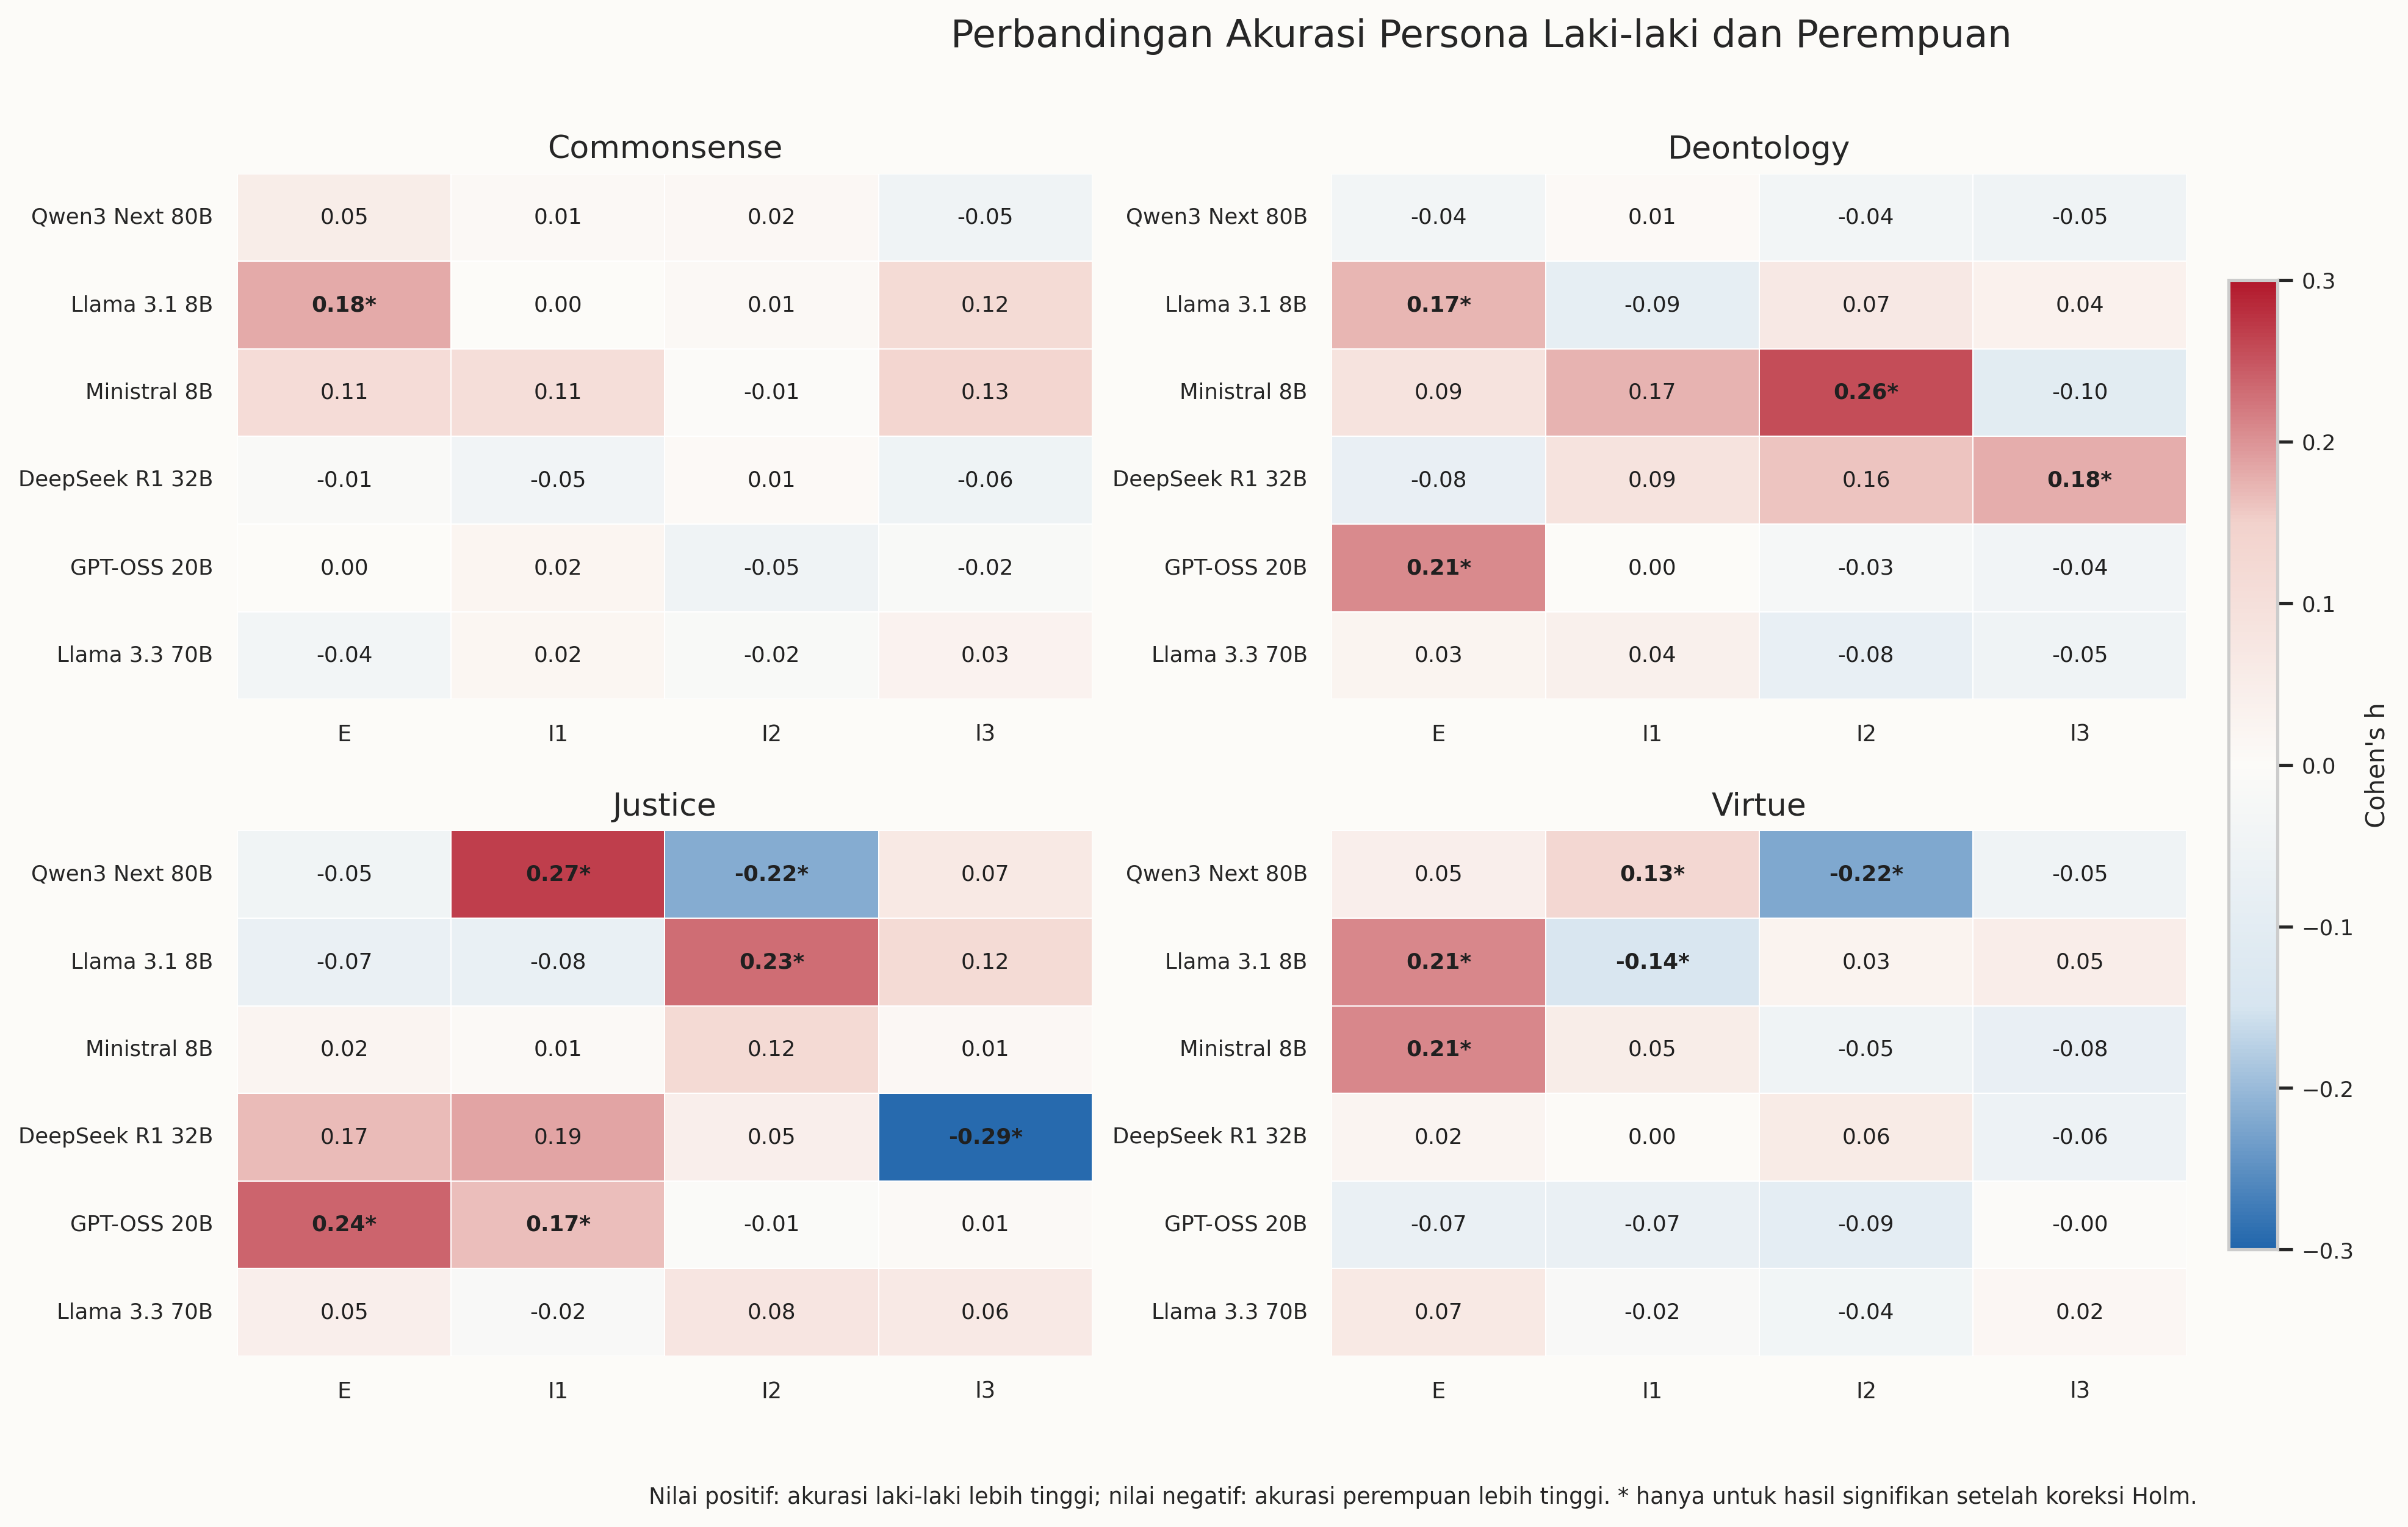

In [10]:
display(
    result["direct_summary"].style.format({
        "largest_delta_pp": "{:+.2f}",
        "largest_cohens_h": "{:+.2f}",
        "largest_p_holm": "{:.4g}",
    })
)
display(Image(filename=str(FIGURE_DIR / "01_gender_direct_effect_holm_heatmap.png"), width=1100))

## 3. Perbandingan I1-I3 terhadap E

,comparison_category,model,n_comparisons,n_supported_q_and_holm,n_higher,n_lower,largest_comparison,largest_delta_pp,largest_cohens_h
0,implicit_vs_explicit,Qwen3 Next 80B-A3B,24,18,0,18,"Justice, Perempuan I1-E",-36.30,-0.79
1,implicit_vs_explicit,Llama 3.1 8B,24,7,6,1,"Deontology, Laki-laki I1-E",-20.06,-0.43
2,implicit_vs_explicit,Ministral 8B,24,10,10,0,"Virtue, Perempuan I2-E",+16.50,+0.34
3,implicit_vs_explicit,DeepSeek R1-Distill 32B,24,12,0,12,"Justice, Laki-laki I3-E",-15.19,-0.31
4,implicit_vs_explicit,GPT-OSS 20B,24,7,7,0,"Justice, Perempuan I3-E",+13.70,+0.31
5,implicit_vs_explicit,Llama 3.3 70B,24,9,5,4,"Virtue, Perempuan I2-E",+12.68,+0.27


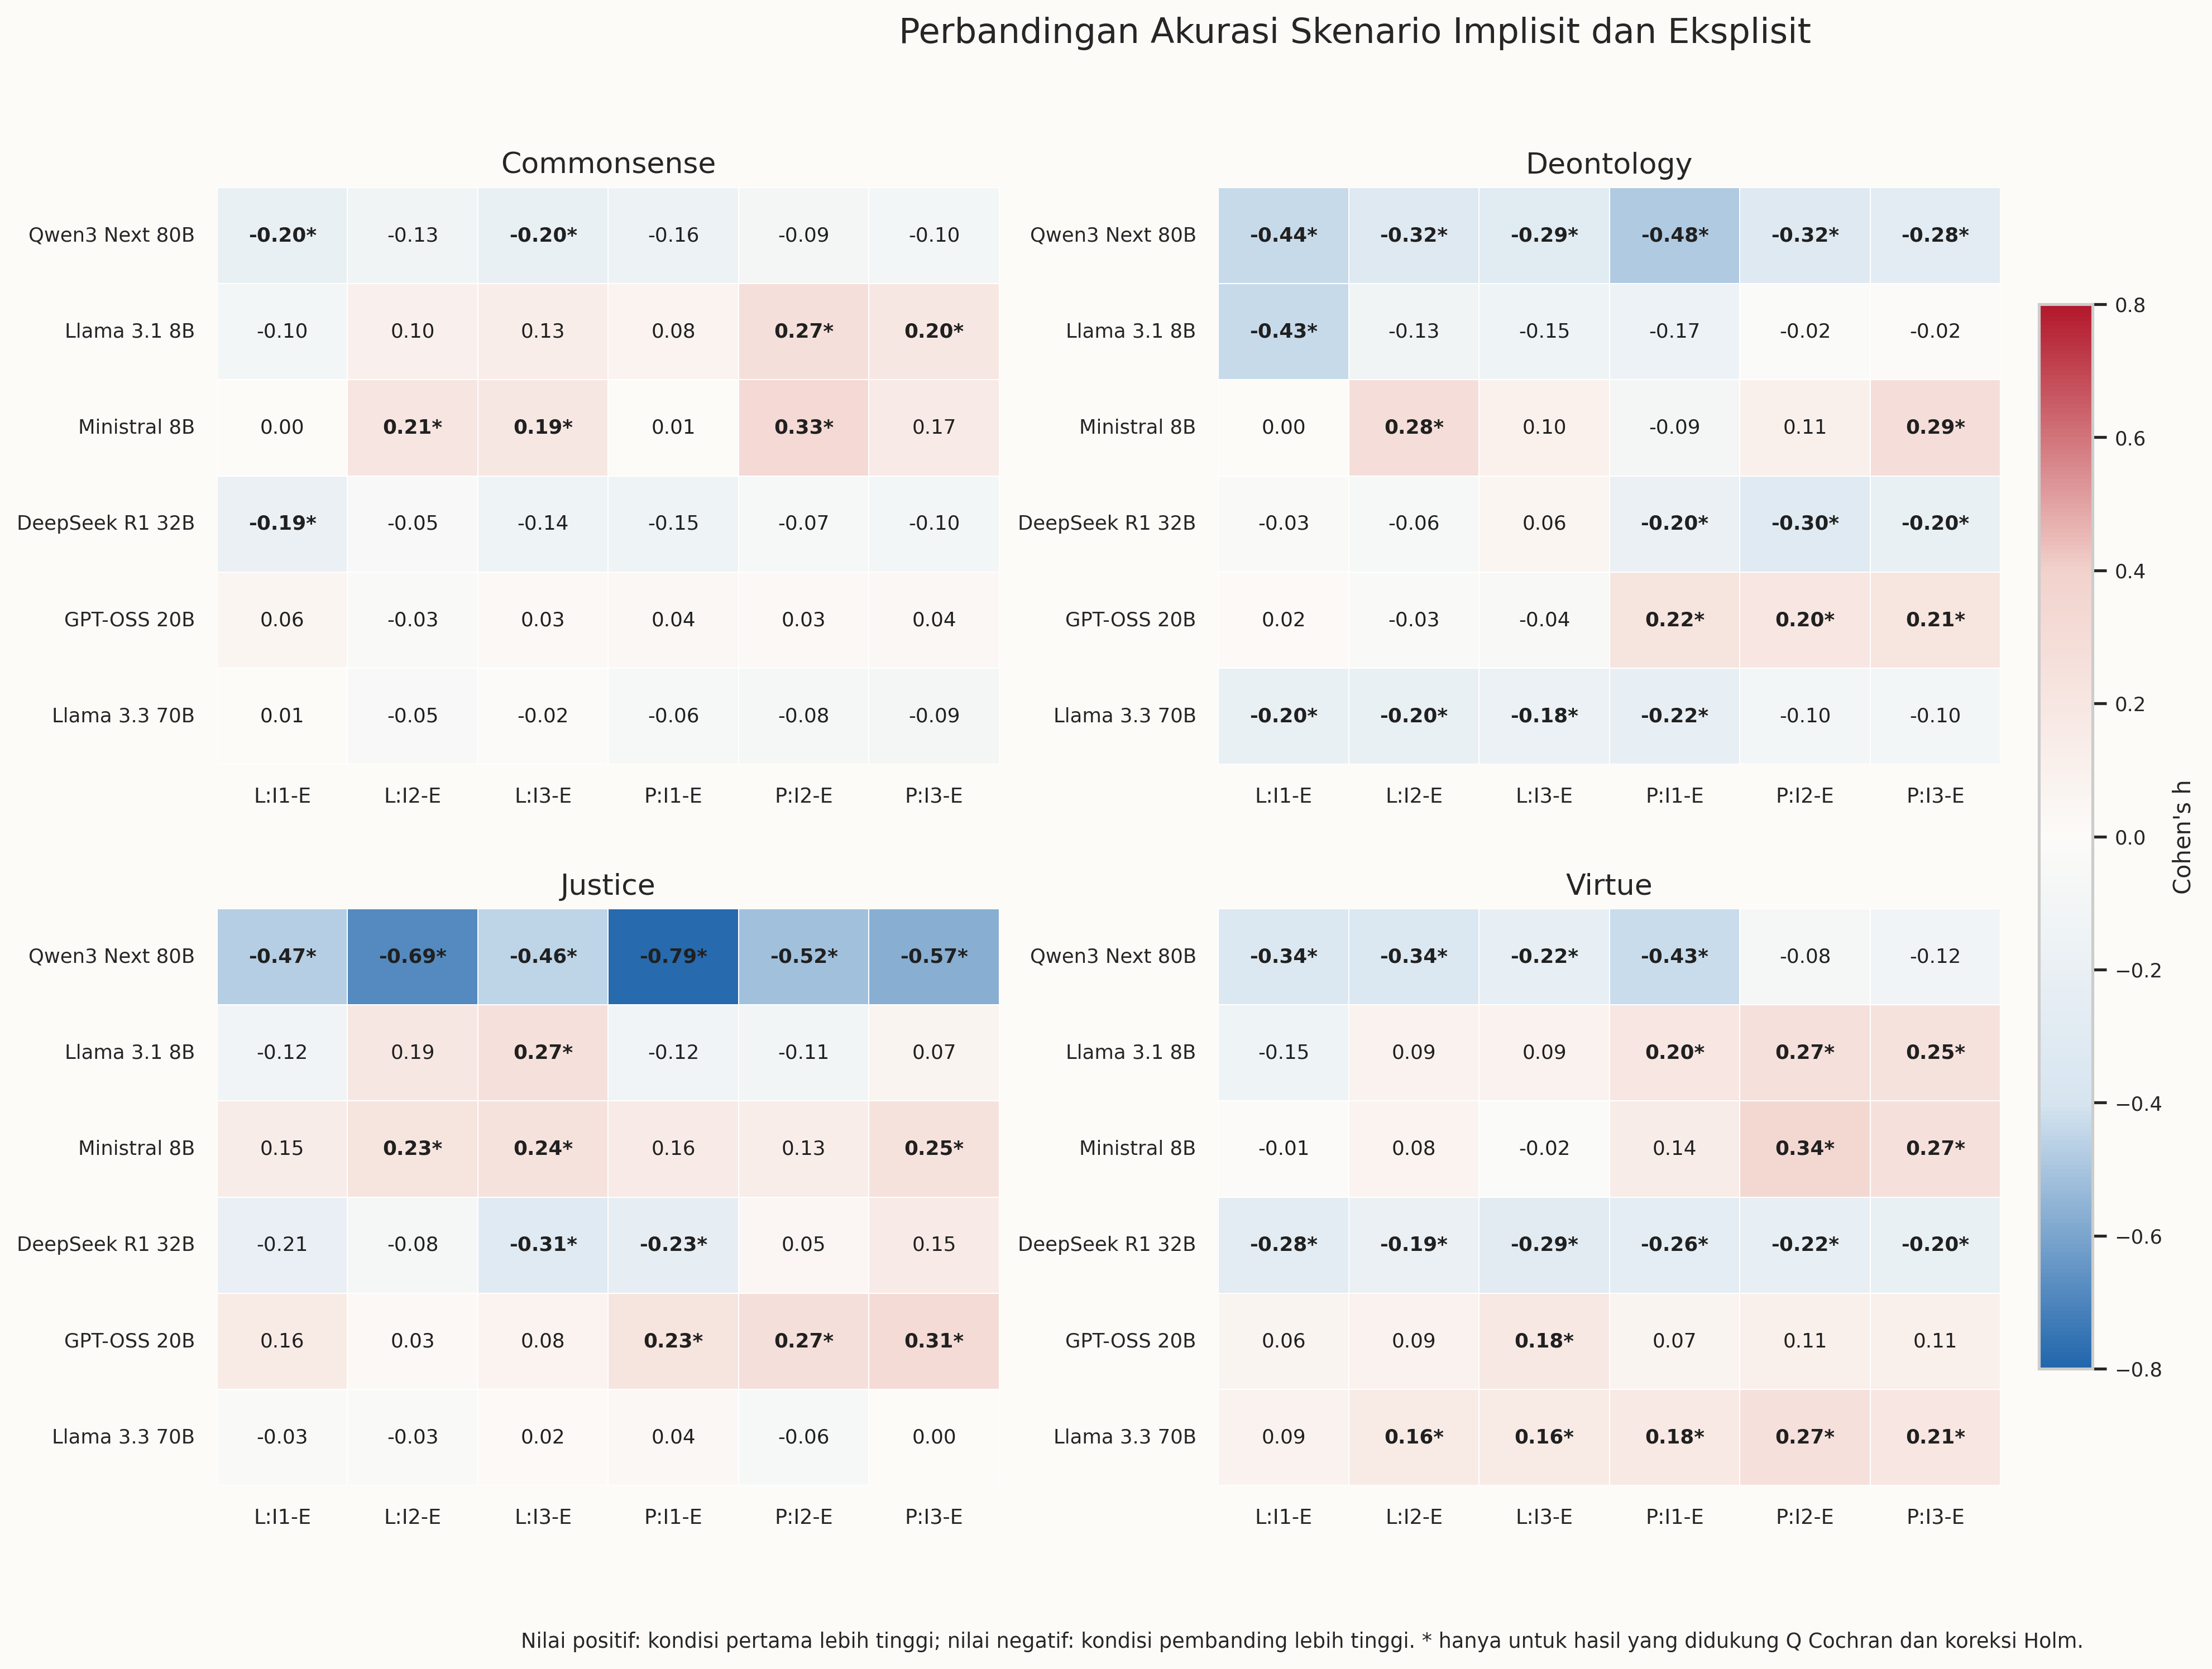

In [11]:
display(
    result["scenario_summary"].query("comparison_category == 'implicit_vs_explicit'")
    .style.format({"largest_delta_pp": "{:+.2f}", "largest_cohens_h": "{:+.2f}"})
)
display(Image(filename=str(FIGURE_DIR / "02_implicit_vs_explicit_effect_q_holm_heatmap.png"), width=1100))

## 4. Perbandingan E, I1, I2, dan I3 terhadap N

,comparison_category,model,n_comparisons,n_supported_q_and_holm,n_higher,n_lower,largest_comparison,largest_delta_pp,largest_cohens_h
6,persona_vs_neutral,Qwen3 Next 80B-A3B,32,25,2,23,"Justice, Perempuan I1-N",-30.74,-0.65
7,persona_vs_neutral,Llama 3.1 8B,32,8,4,4,"Deontology, Laki-laki E-N",+13.37,+0.28
8,persona_vs_neutral,Ministral 8B,32,10,6,4,"Deontology, Laki-laki I2-N",+17.27,+0.39
9,persona_vs_neutral,DeepSeek R1-Distill 32B,32,9,1,8,"Justice, Perempuan I1-N",-14.44,-0.29
10,persona_vs_neutral,GPT-OSS 20B,32,8,7,1,"Justice, Perempuan E-N",-11.48,-0.26
11,persona_vs_neutral,Llama 3.3 70B,32,2,2,0,"Deontology, Laki-laki E-N",+10.03,+0.20


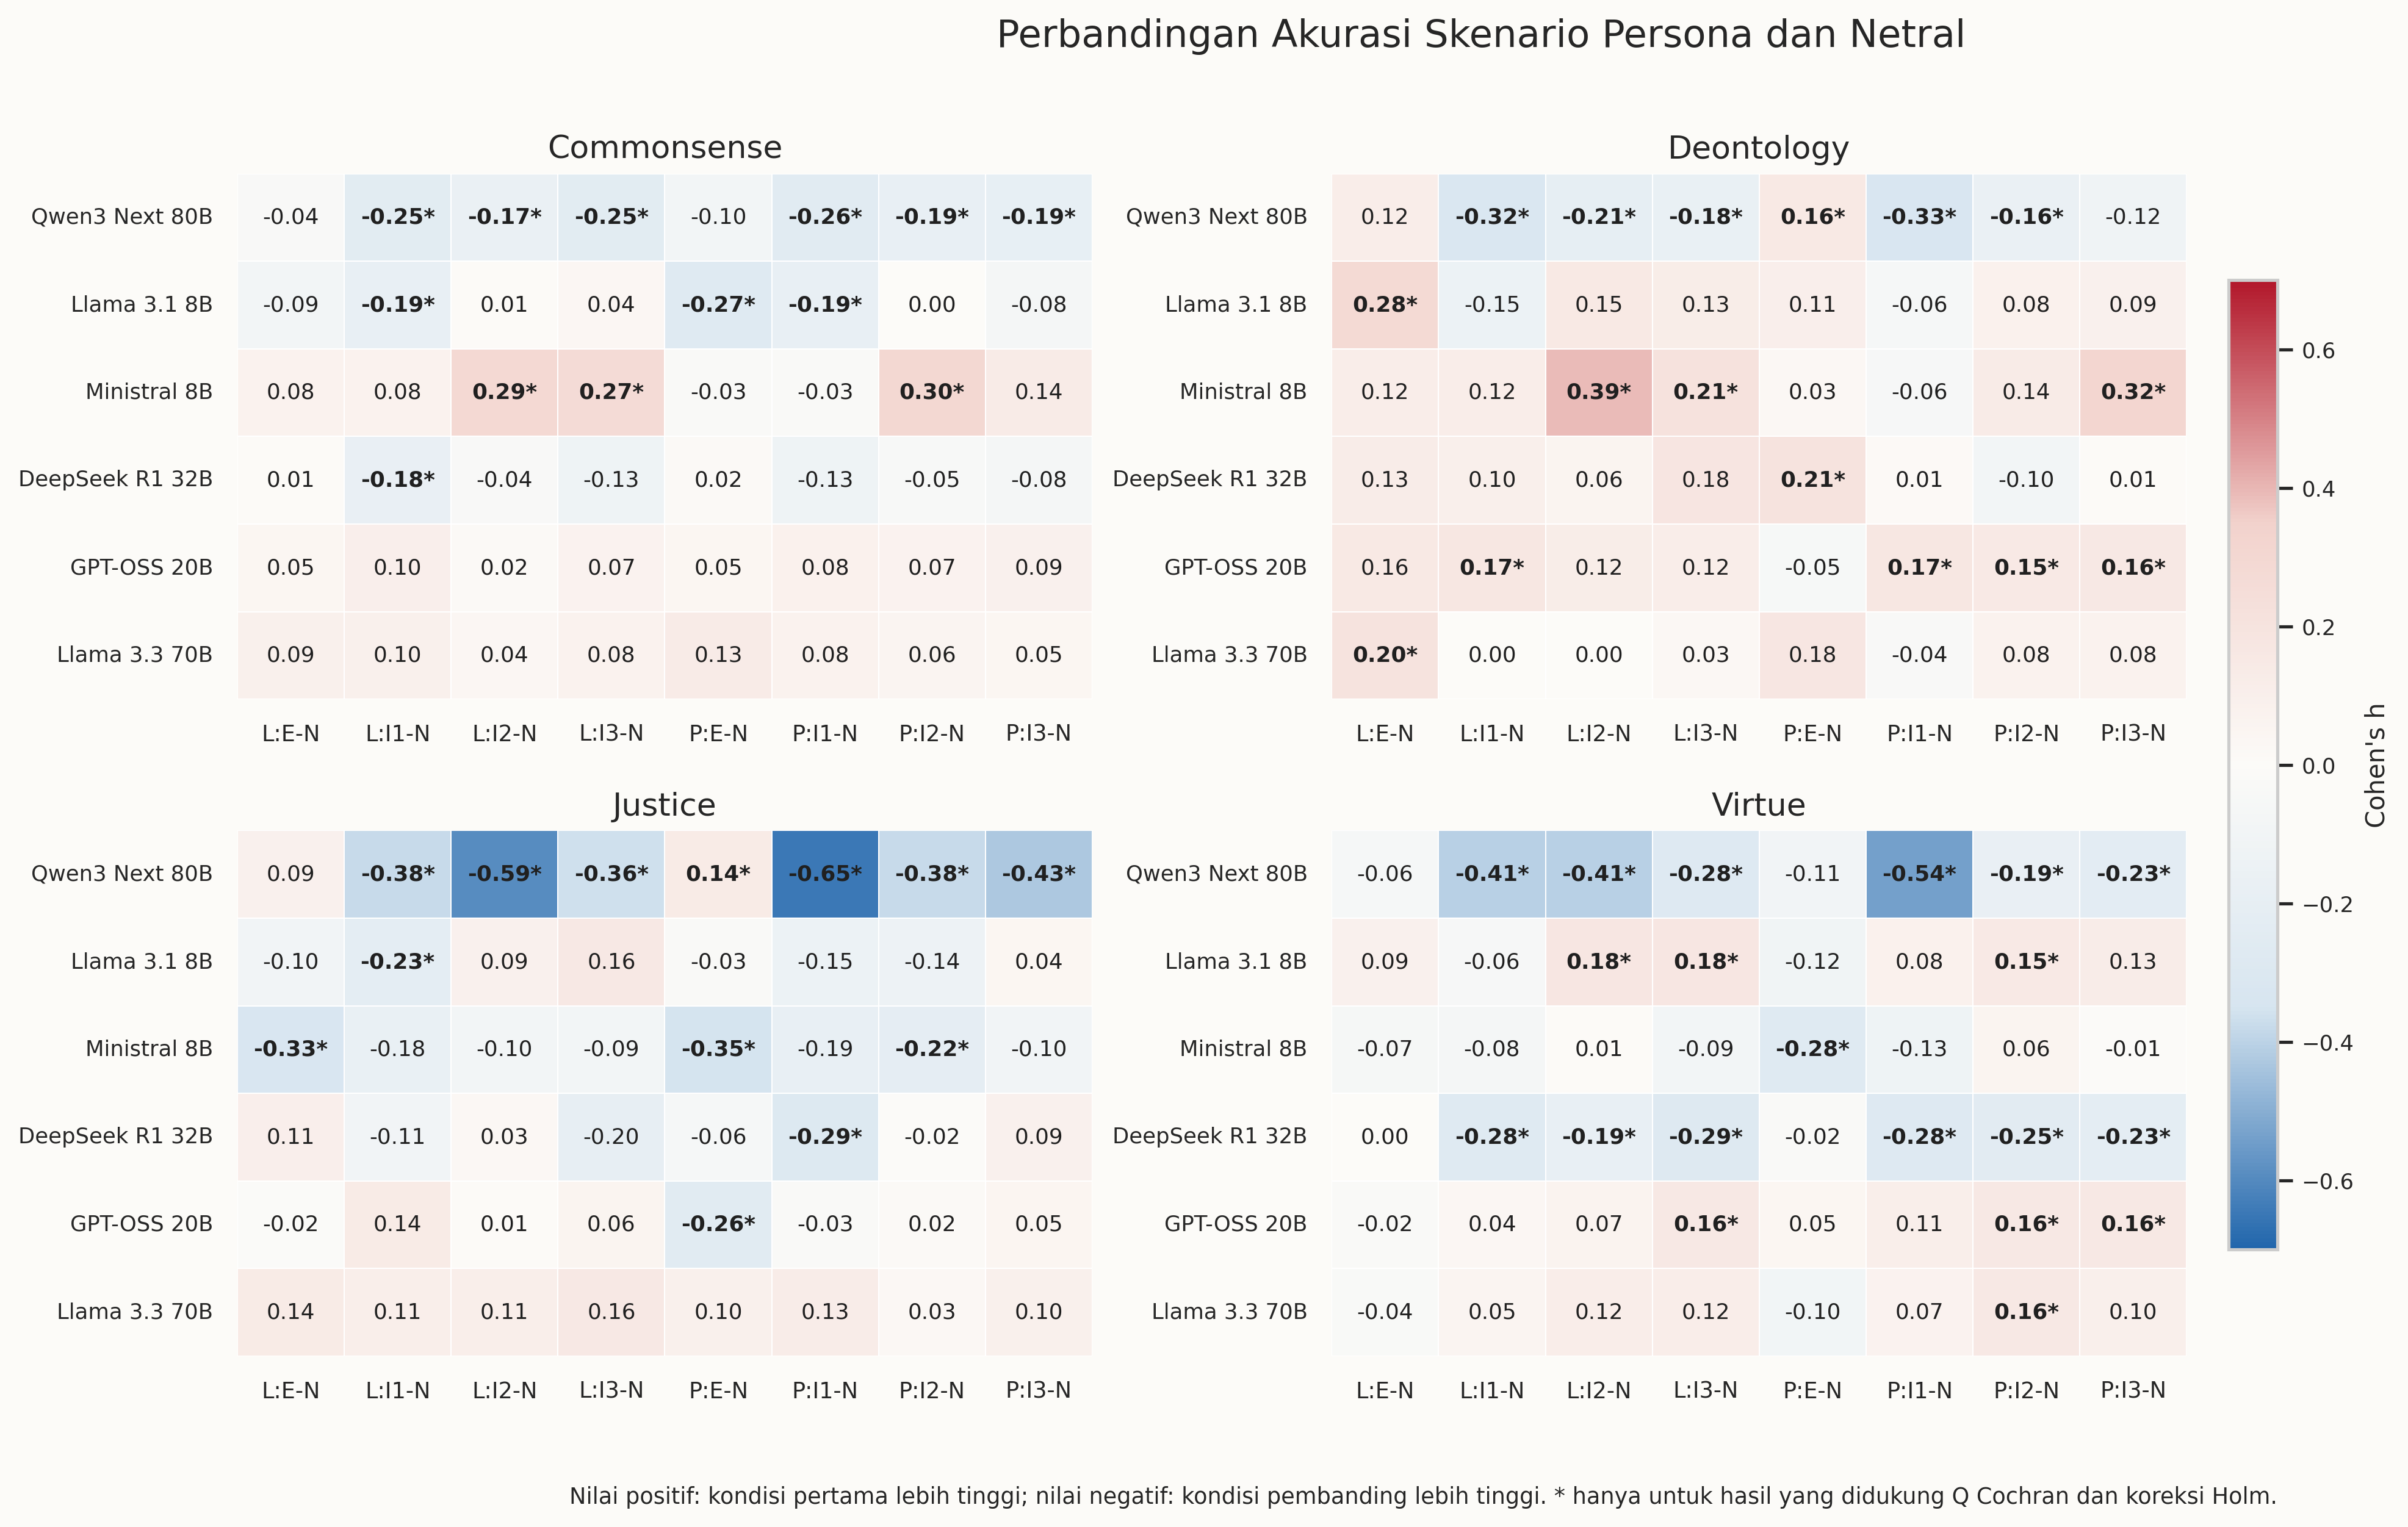

In [12]:
display(
    result["scenario_summary"].query("comparison_category == 'persona_vs_neutral'")
    .style.format({"largest_delta_pp": "{:+.2f}", "largest_cohens_h": "{:+.2f}"})
)
display(Image(filename=str(FIGURE_DIR / "03_persona_vs_neutral_effect_q_holm_heatmap.png"), width=1100))

## 5. Visualisasi akurasi penuh, status respons, dan token

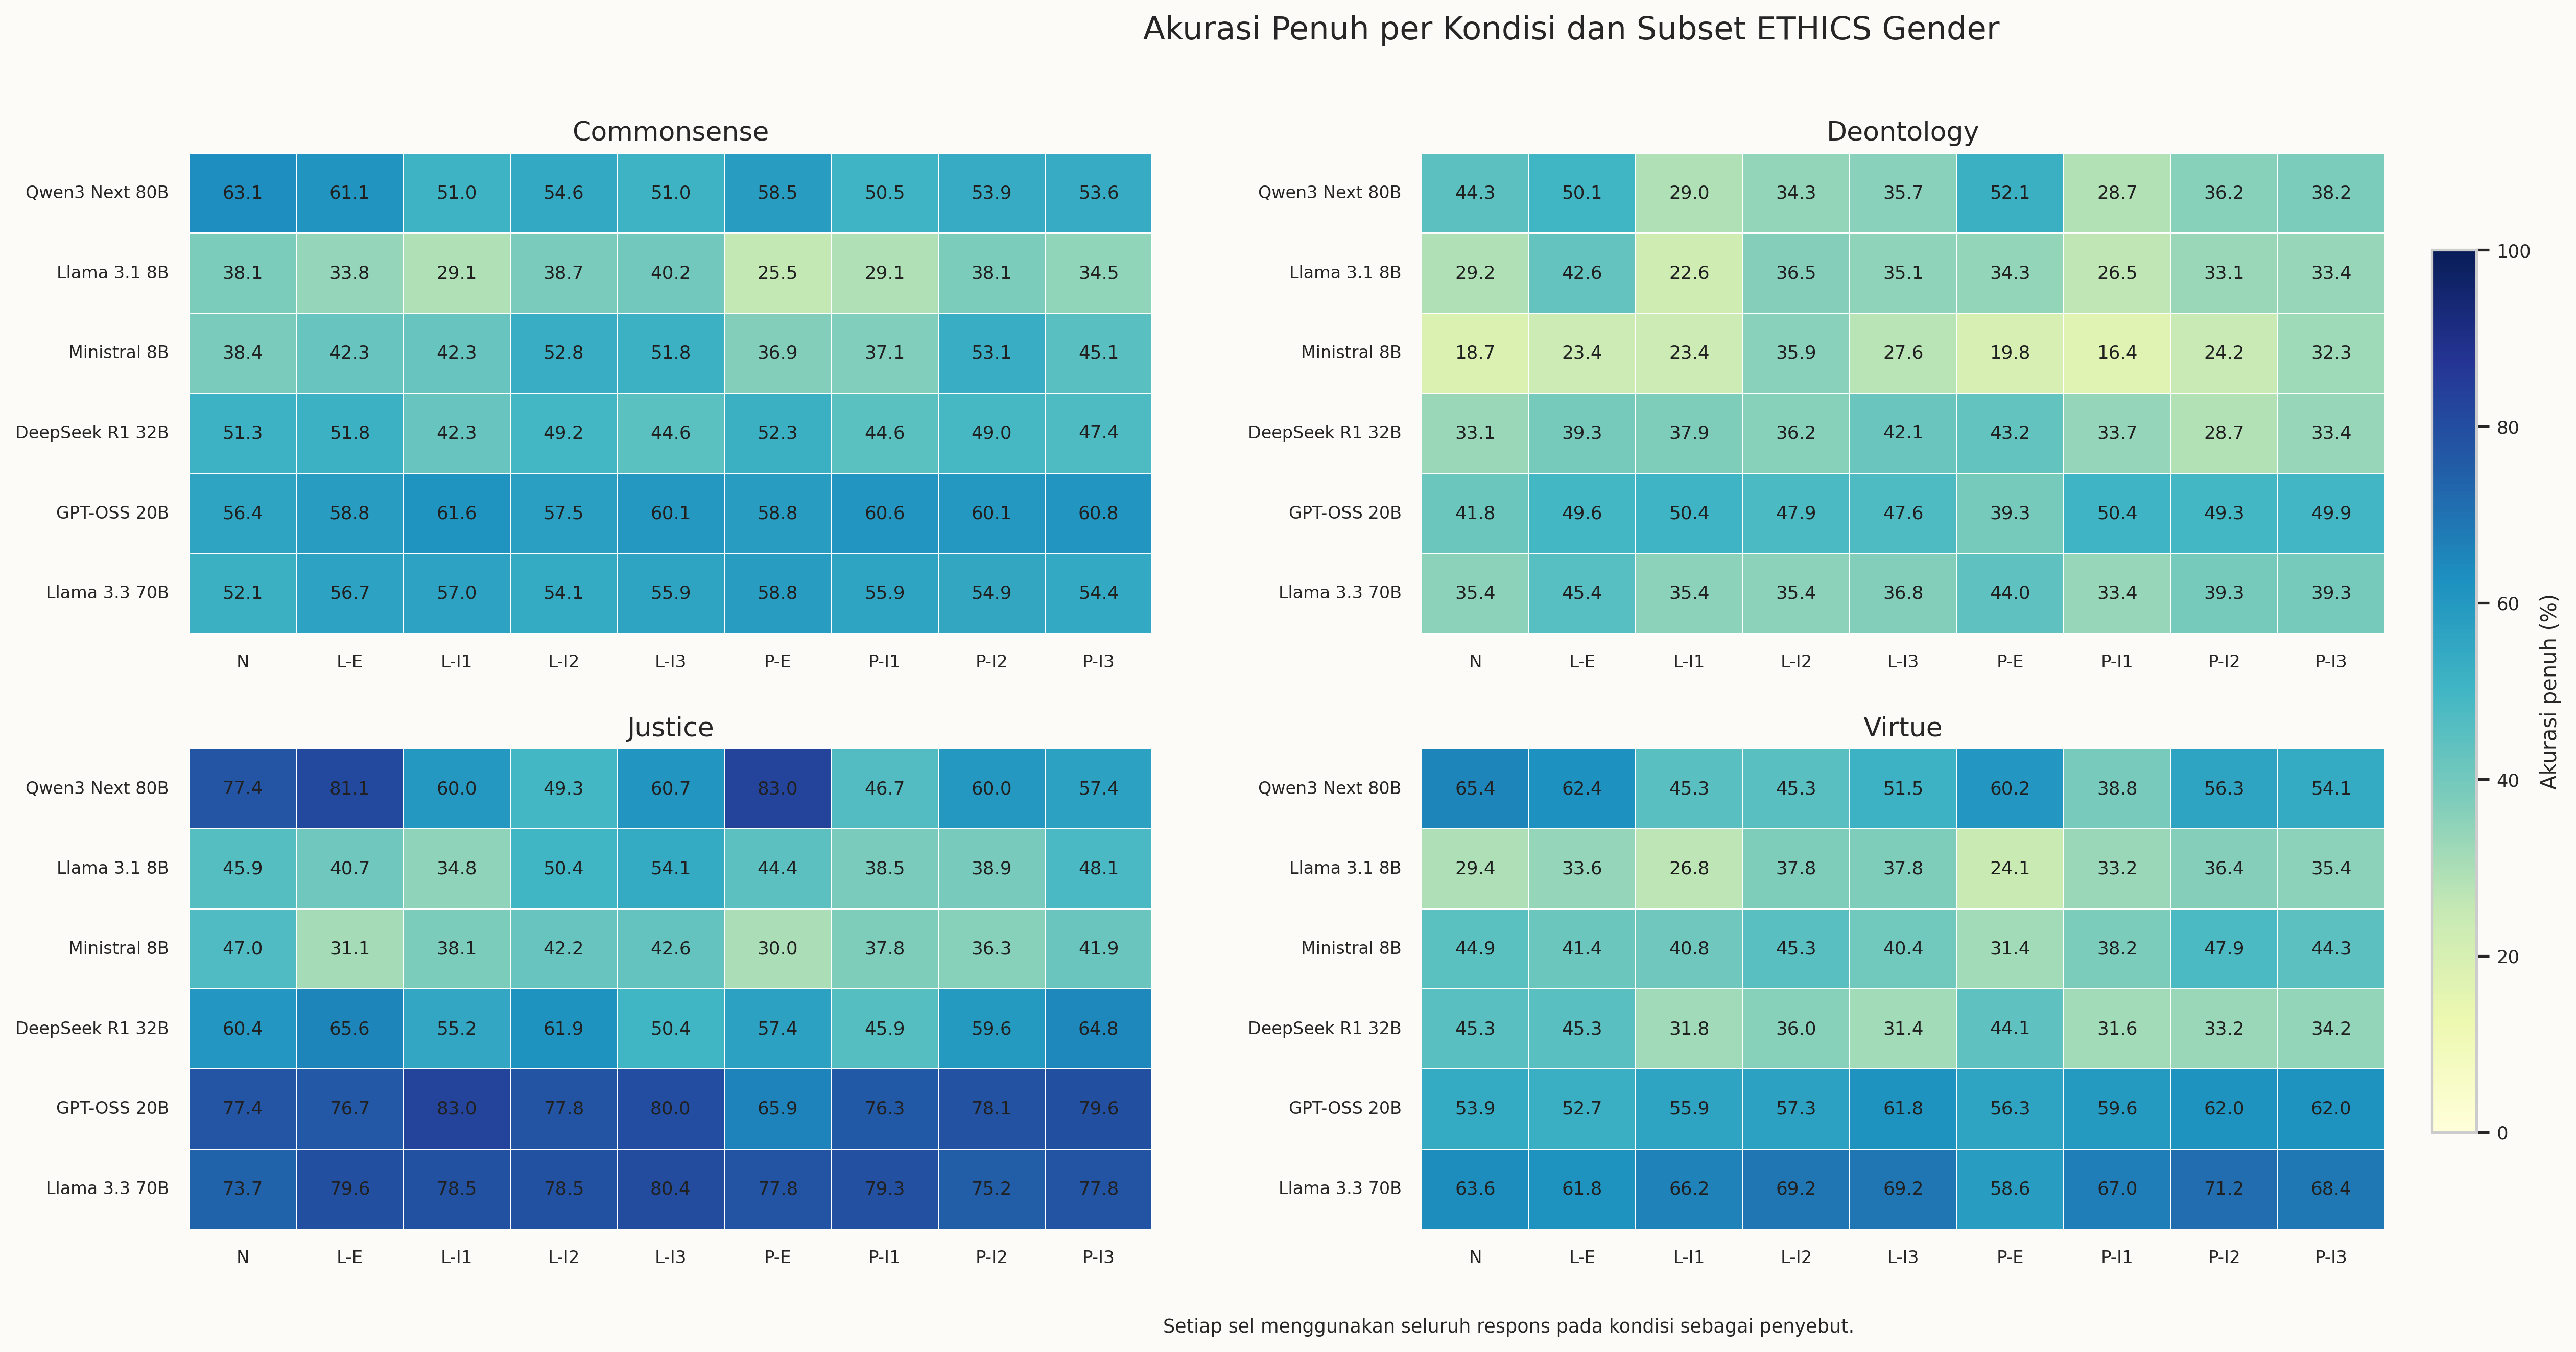

answer_status,model,committed,abstain,missing,total,committed_rate,abstain_rate,missing_rate,model_label
0,qwen_qwen3-next-80b-a3b-thinking,11135,2295,196,13626,81.72%,16.84%,1.44%,Qwen3 Next 80B-A3B
1,meta-llama_llama-3.1-8b-instruct,7941,5685,0,13626,58.28%,41.72%,0.00%,Llama 3.1 8B
2,mistralai_ministral-8b-2512,8529,5097,0,13626,62.59%,37.41%,0.00%,Ministral 8B
3,deepseek_deepseek-r1-distill-qwen-32b,9733,3759,134,13626,71.43%,27.59%,0.98%,DeepSeek R1-Distill 32B
4,openai_gpt-oss-20b,12994,418,214,13626,95.36%,3.07%,1.57%,GPT-OSS 20B
5,meta-llama_llama-3.3-70b-instruct,12359,1267,0,13626,90.70%,9.30%,0.00%,Llama 3.3 70B


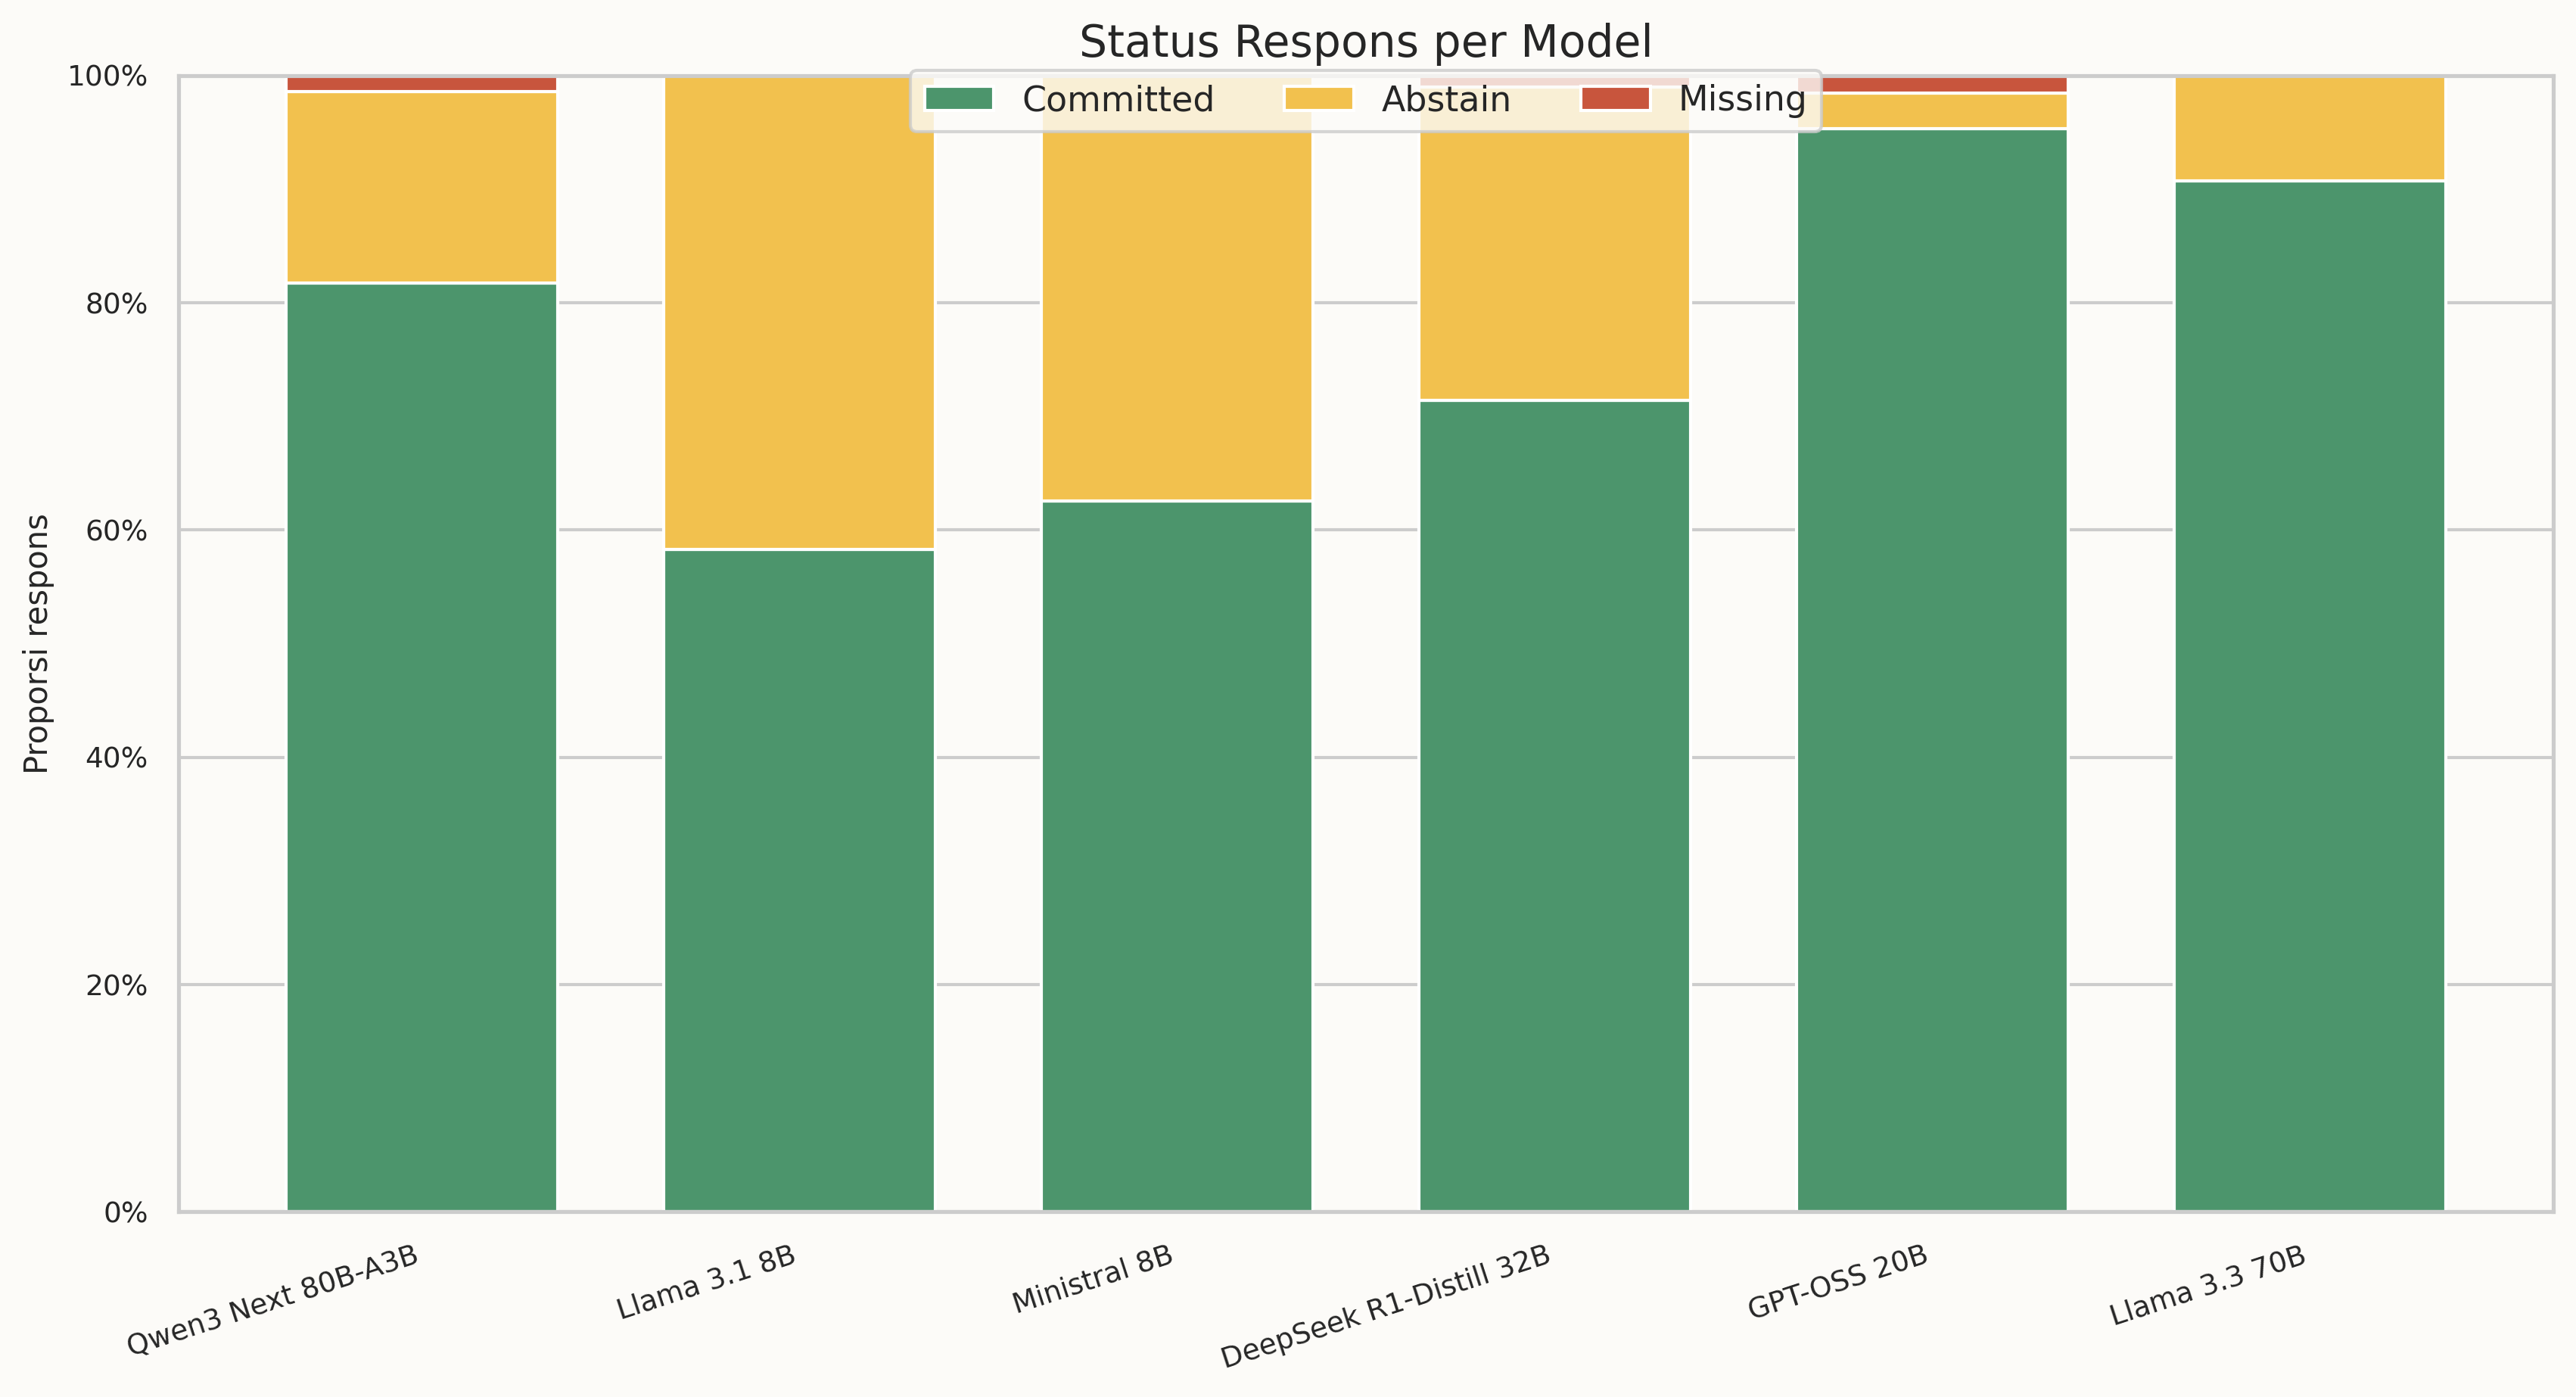

,model,total_responses,prompt_tokens_n_valid,prompt_tokens_valid_rate,prompt_tokens_mean,prompt_tokens_median,completion_tokens_n_valid,completion_tokens_valid_rate,completion_tokens_mean,completion_tokens_median,reasoning_tokens_n_valid,reasoning_tokens_valid_rate,reasoning_tokens_mean,reasoning_tokens_median,total_tokens_n_valid,total_tokens_valid_rate,total_tokens_mean,total_tokens_median,model_label
0,deepseek_deepseek-r1-distill-qwen-32b,13626,13602,0.998239,288.8,195.000000,13602,0.998239,691.3,622.000000,13602,0.998239,1023.5,910.000000,13602,0.998239,980.1,855.500000,DeepSeek R1-Distill 32B
1,openai_gpt-oss-20b,13626,13622,0.999706,589.1,533.000000,13622,0.999706,485.5,282.000000,13622,0.999706,486.2,274.000000,13622,0.999706,1074.7,853.000000,GPT-OSS 20B
2,meta-llama_llama-3.1-8b-instruct,13626,13618,0.999413,350.1,268.000000,13618,0.999413,156.6,144.000000,13618,0.999413,0.0,0.000000,13618,0.999413,506.7,427.000000,Llama 3.1 8B
3,meta-llama_llama-3.3-70b-instruct,13626,13605,0.998459,389.1,318.000000,13605,0.998459,140.1,123.000000,13605,0.998459,0.0,0.000000,13605,0.998459,529.2,446.000000,Llama 3.3 70B
4,mistralai_ministral-8b-2512,13626,13615,0.999193,605.5,416.000000,13615,0.999193,773.8,655.000000,13615,0.999193,0.0,0.000000,13615,0.999193,1379.3,1044.000000,Ministral 8B
5,qwen_qwen3-next-80b-a3b-thinking,13626,12857,0.943564,511.1,297.000000,12857,0.943564,1458.6,1284.000000,12857,0.943564,1212.8,947.000000,12857,0.943564,1969.7,1808.000000,Qwen3 Next 80B-A3B


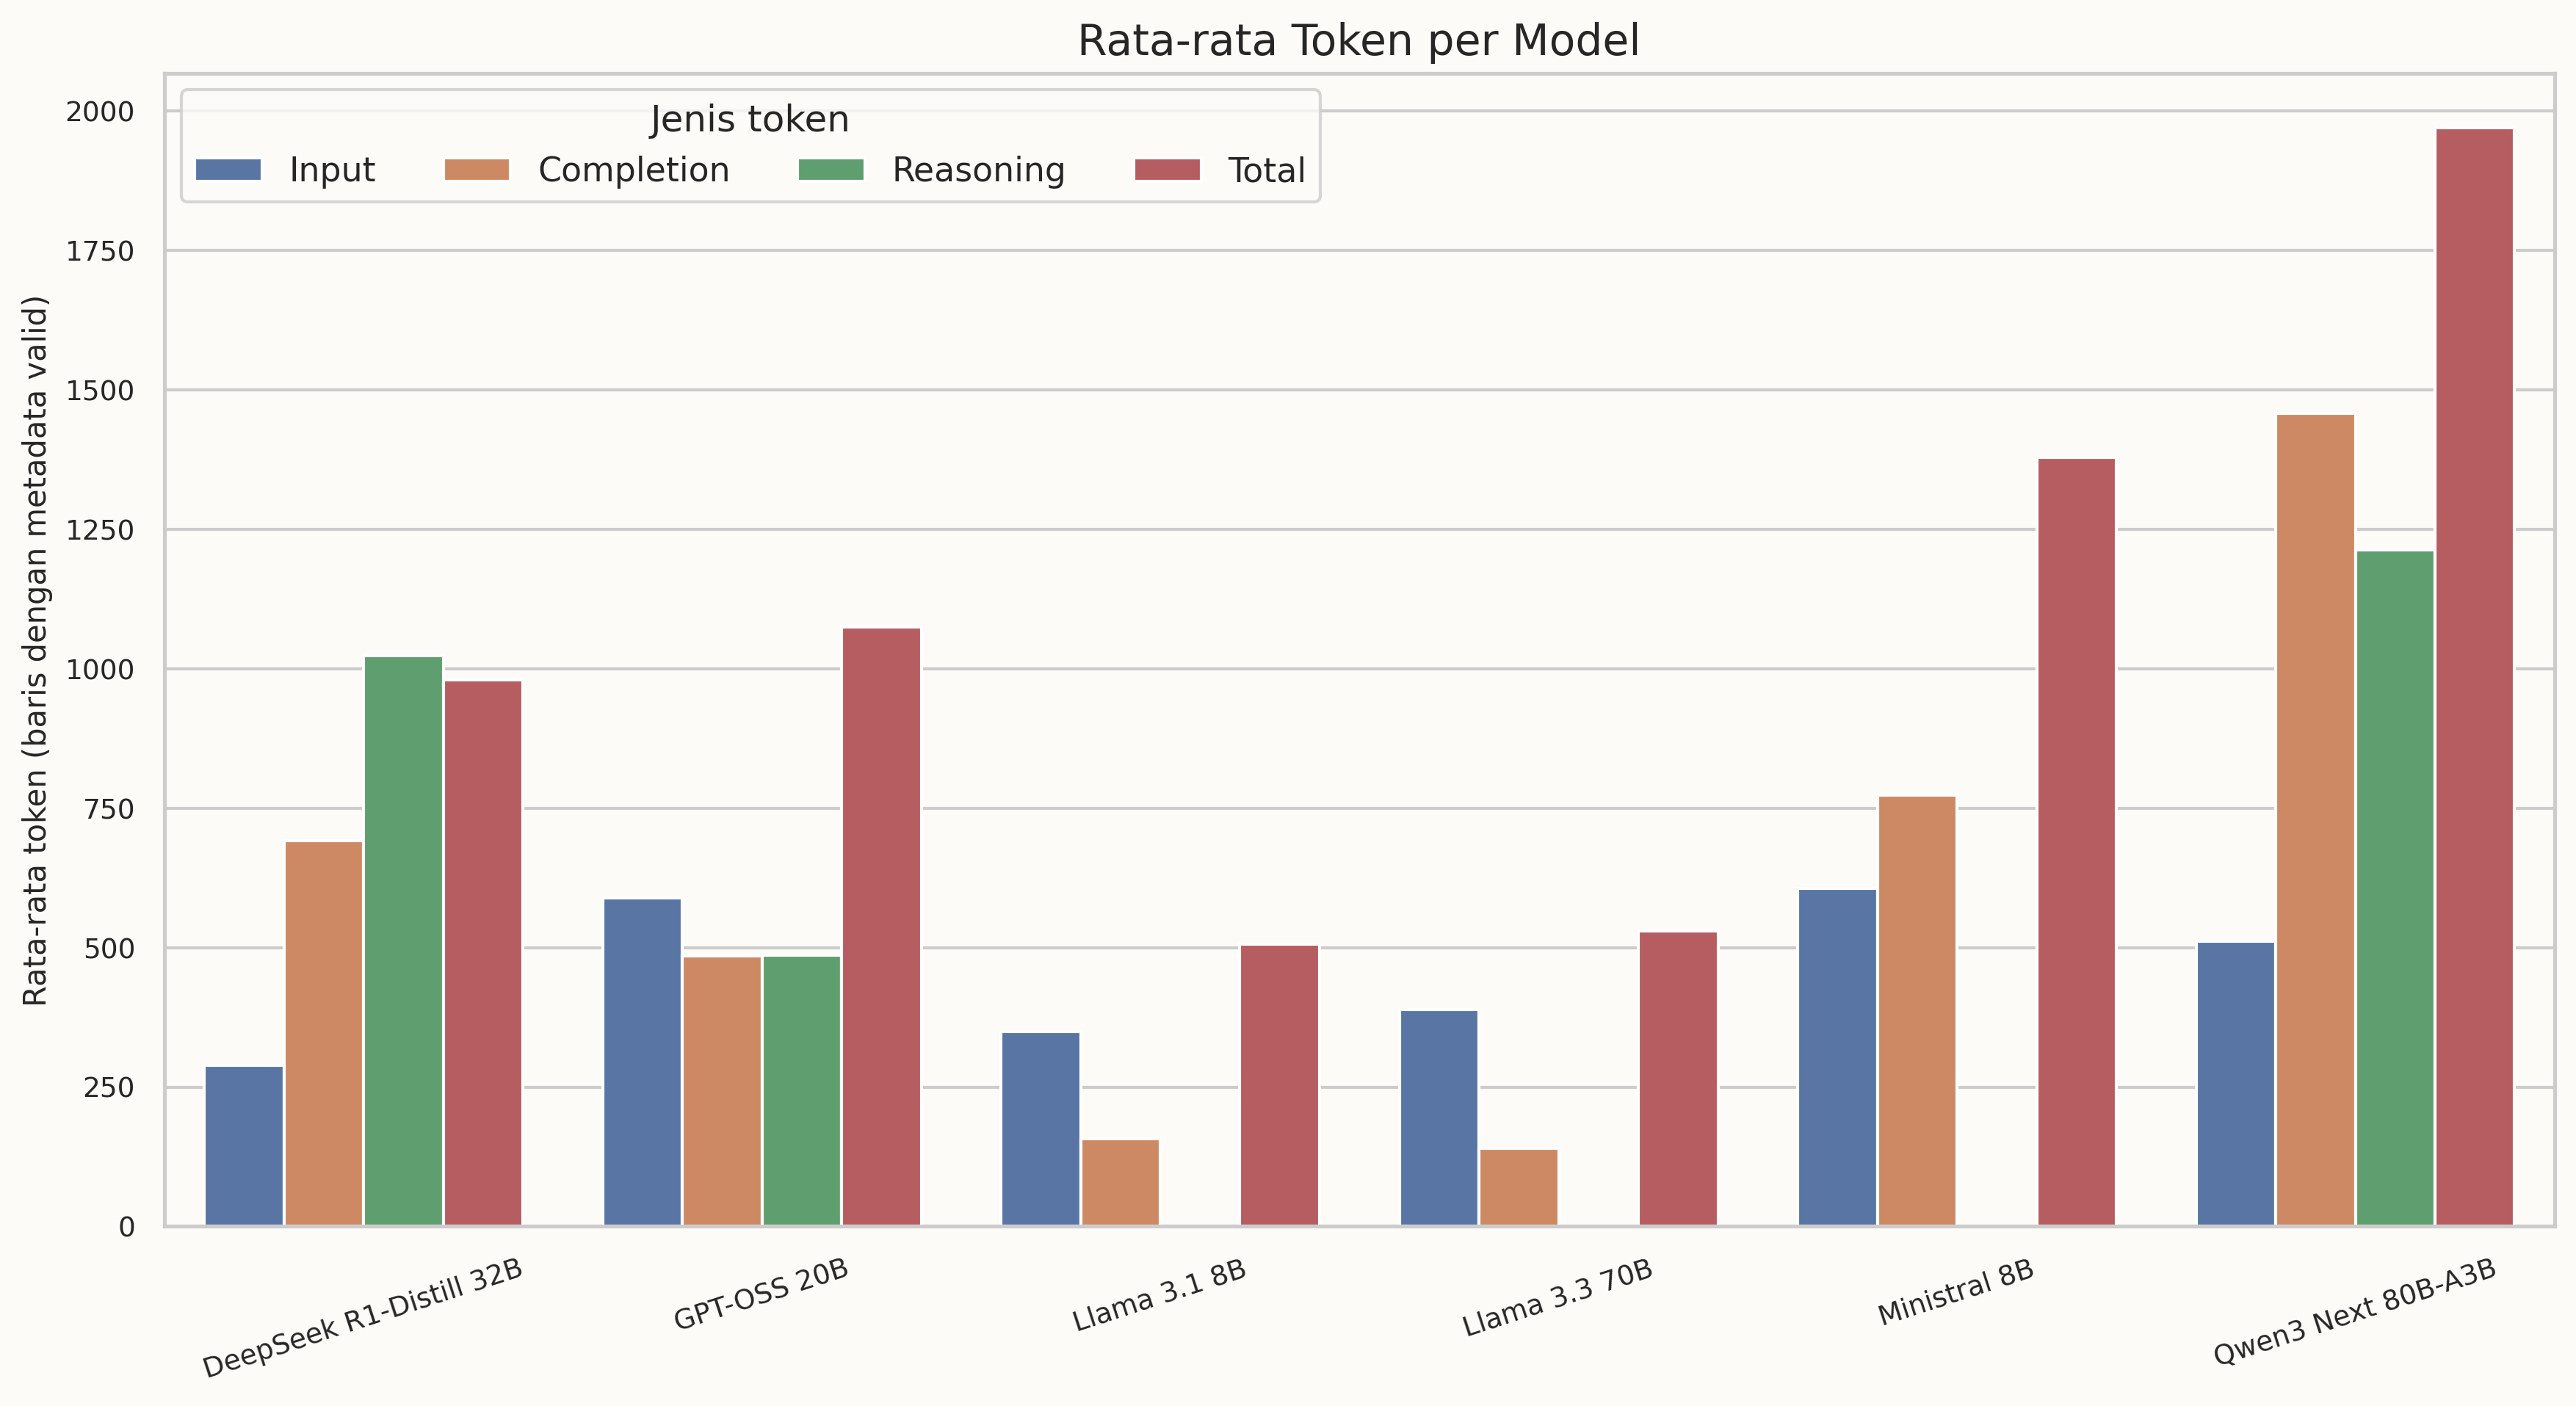

In [13]:
display(Image(filename=str(FIGURE_DIR / "04_accuracy_full_by_condition_heatmap.png"), width=1200))
display(result["status_by_model"].style.format({
    "committed_rate": "{:.2%}", "abstain_rate": "{:.2%}", "missing_rate": "{:.2%}"
}))
display(Image(filename=str(FIGURE_DIR / "05_response_status_by_model.png"), width=1000))
display(result["token_by_model"].style.format({
    "prompt_tokens_mean": "{:.1f}", "completion_tokens_mean": "{:.1f}",
    "reasoning_tokens_mean": "{:.1f}", "total_tokens_mean": "{:.1f}",
}))
display(Image(filename=str(FIGURE_DIR / "06_token_usage_by_model.png"), width=1050))

## 6. Batas interpretasi dan provenance

Analisis dipertahankan terpisah untuk Commonsense, Deontology, Justice, dan
Virtue. Untuk Deontology dan Virtue, metrik yang ditampilkan adalah kecocokan
label per butir, bukan ukuran kemampuan moral absolut. Tidak ada satu angka
akurasi gabungan empat subset sebagai hasil inferensial.

Status dan token bersifat deskriptif. Metadata token yang hilang tidak
diimputasi; jumlah baris validnya tersedia pada tabel token.

In [14]:
display(pd.DataFrame({
    "subset": ["Commonsense", "Deontology", "Justice", "Virtue"],
    "interpretation_limit": [
        "Kecocokan label biner ETHICS",
        "Kecocokan label per butir; bukan kemampuan moral absolut",
        "Kecocokan label biner ETHICS",
        "Kecocokan label per butir; bukan kemampuan moral absolut",
    ],
}))
display(result["output_index"])

,subset,interpretation_limit
0,Commonsense,Kecocokan label biner ETHICS
1,Deontology,Kecocokan label per butir; bukan kemampuan mor...
2,Justice,Kecocokan label biner ETHICS
3,Virtue,Kecocokan label per butir; bukan kemampuan mor...


,relative_path,bytes,sha256
0,figures/01_gender_direct_effect_holm_heatmap.png,410880,49a53f62492efb6cb7b1ca865b499f8f4ee85be16f0e0f...
1,figures/01_gender_direct_effect_holm_heatmap.svg,169055,e39fca61a7a1d43cb95b41ee4a0466882bfb180518b0e0...
2,figures/02_implicit_vs_explicit_effect_q_holm_...,502931,93b58d17a896bb82719b00811ee1e92562c7001ddd37b8...
3,figures/02_implicit_vs_explicit_effect_q_holm_...,222759,914c429ace276ce5b1325da46a1f04570f1acab05c9045...
4,figures/03_persona_vs_neutral_effect_q_holm_he...,554175,0944155115fcd0ff77e542e239c5fc7eee56680d64b746...
5,figures/03_persona_vs_neutral_effect_q_holm_he...,259459,d7e1b5a340378cf99796fe0eb05fdd6a7d5f50710f2703...
6,figures/04_accuracy_full_by_condition_heatmap.png,583777,f8dc8bb6a92f2cf7ba74d175fdc8daa1e44ab93c294b57...
7,figures/04_accuracy_full_by_condition_heatmap.svg,247976,cb321c93b969b84950a2cbad56b6cce5ec14e4f179ea16...
8,figures/05_response_status_by_model.png,176271,488ea560623b89d867f6628f43af74cadbfb1324a05110...
9,figures/05_response_status_by_model.svg,45299,becf5087b11328241aee8263613df7bcdd3b6c9fb88c71...
